# Multiple Linear Regression From Scratch

## Mini Hands-on Exercise

In this exercise, I implement a multiple linear regression model using NumPy without using Scikit-learn.

The model learns the relationship between house features and house prices using gradient descent.

### Objectives
- Load and understand a small dataset.
- Implement prediction, feature scaling, and target scaling.
- Train the model using gradient descent.
- Evaluate predictions using MAE, MSE, and RMSE.
- Predict prices for unseen inputs.
- Visualize predictions and residuals.
- Save the trained model parameters and preprocessing statistics for future use.

**Note:** This is a learning exercise using synthetic data, not a production-ready house-price prediction system.

## 1. Import Libraries and Create a Dataset

NumPy is used for numerical operations, matrix multiplication, and gradient descent. Matplotlib is used to visualize model predictions and residuals.

For this exercise, I create a small synthetic dataset with two input features:

- House size in square feet
- Number of bedrooms

The target variable, `y`, represents the house price.

In [2]:
import numpy as np
from matplotlib import pyplot as plt

X = np.array([
    [1000, 2],
    [1500, 3],
    [2000, 4]
])
y = np.array([16000,23000,32000])

print("Done")

Done


## 2. Define Prediction, Scaling, and Training Functions

### Prediction function

Multiple linear regression predicts a target using a weighted sum of input features and a bias:

\[
\hat{y}=Xw+b
\]

Here, `w` contains one weight for each feature, and `b` is the bias.

### Scaling function

Feature scaling standardizes each input feature using its mean and standard deviation. Target scaling standardizes the house prices so gradient descent can train more comfortably with the selected learning rate.

The function also returns the scaling statistics so predictions can later be converted back to the original price scale.

### Training function

The model is trained using gradient descent. At each epoch, it calculates prediction errors, computes the gradients of the mean squared error, and updates the weights and bias.

In [3]:
def predict(x,w,b):
    return x@w+b
def scaling(x,y):
    # X scaling
    x_mean = x.mean(axis=0)
    x_std = x.std(axis=0)
    x_scaled = (x-x_mean)/x_std
    # Y scaling
    y_mean = y.mean()
    y_std = y.std()
    y_scaled = (y - y_mean) / y_std
    return x_scaled, y_scaled, x_mean, x_std, y_mean, y_std

def train(x,y):
    x, y, x_mean, x_std, y_mean, y_std = scaling(x, y)
    epochs = 1000
    lr = 0.1
    w = np.zeros(x.shape[1])
    b = 0.0
    n = len(x)
    loss_history = []
    for epoch in range(epochs):
        y_pred = predict(x,w,b)
        error = y_pred - y
        loss = np.sum((error)**2)/n

        dw = (2/n) * (x.T@error)
        db = (2/n) * np.sum(error)

        w = w - lr*dw
        b = b - lr*db

        loss_history.append(loss)
    return w, b, x_mean, x_std, y_mean, y_std
print("Done")

Done


## 3. Train the Model

I train the model on the input features and target prices.

The training function returns the learned weights and bias, together with the means and standard deviations needed to preprocess future inputs and reverse the target scaling.

These values will be reused for evaluation, unseen predictions, and saving the model.

In [ ]:
w, b, x_mean, x_std, y_mean, y_std = train(X, y)

print("Trained weights:", w)
print("Trained bias:", b)
print("Feature means:", x_mean)
print("Feature standard deviations:", x_std)
print("Target mean:", y_mean)
print("Target standard deviation:", y_std)

## 4. Evaluate Predictions Using Loss Metrics

After training, I standardize the input features using the statistics calculated from the training data. The model generates predictions in standardized target units, which I convert back to the original price scale.

I evaluate the predictions using three metrics:

- **MAE:** Mean Absolute Error, the average absolute difference between actual and predicted values.
- **MSE:** Mean Squared Error, the average squared difference between actual and predicted values.
- **RMSE:** Root Mean Squared Error, the square root of MSE, expressed in the original target units.

These results measure performance on the training examples because the same three examples were used to fit the model.

In [23]:
import math
def mse(y_true, y_pred):
    error = y_true - y_pred
    MSE = np.mean(error ** 2)
    return MSE
def mae(y_true,y_pred):
    error = y_true - y_pred
    MAE = np.mean(np.abs(error))
    return MAE
def rmse(y_true,y_pred):
    mse_value = mse(y_true,y_pred)
    RMSE = math.sqrt(mse_value)
    return RMSE
print("Done")

Done


### Scaling X function

In [39]:
def scaleX(x,x_mean,x_std):
    return (x-x_mean)/x_std
print("Done")

Done


### Test

In [40]:
w, b, x_mean, x_std, y_mean, y_std = train(X, y)
x_scaled = scaleX(X,x_mean,x_std)
y_pred_scaled = predict(x_scaled, w, b)
y_pred = y_pred_scaled * y_std + y_mean  # Back to orginal scale

print("Actual prices:", y)
print("Predicted prices:", np.round(y_pred, 2))

mse_values = mse(y,y_pred)
mae_values = mae(y,y_pred)
rmse_values = rmse(y,y_pred)
print(f"MSE : {mse_values:.2f}")
print(f"MAE : {mae_values:.2f}")
print(f"RMSE : {rmse_values:.2f}")

Actual prices: [16000 23000 32000]
Predicted prices: [15666.67 23666.67 31666.67]
MSE : 222222.22
MAE : 444.44
RMSE : 471.40


## 6. Visualize Actual vs. Predicted Prices

I compare actual prices with the model's predicted prices using a scatter plot.

The horizontal axis represents the training example index, while the vertical axis represents price. This format is appropriate here because the model has two input features, so house size alone does not fully describe its predictions.

Close agreement between the actual and predicted points indicates a better fit on these examples.

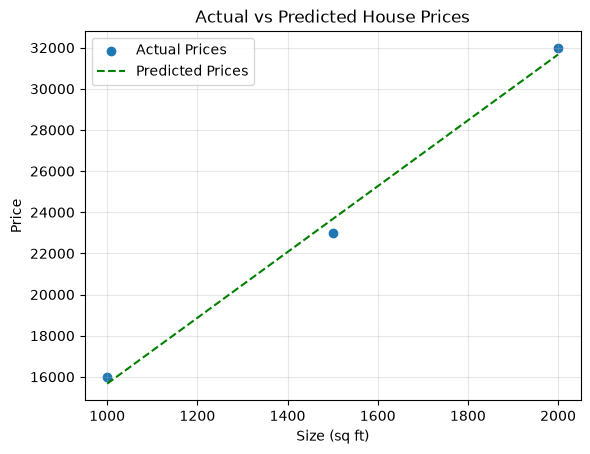

In [48]:
plt.scatter(X[:, 0], y, label="Actual Prices")
plt.plot(X[:, 0], y_pred, label="Predicted Prices",color= "g",linestyle="--")

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Size (sq ft)")
plt.ylabel("Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Test on Unseen Data

I test the trained model using a new input that was not included in the training examples.

The new input contains house size and number of bedrooms. I apply the original training feature statistics, make the prediction, and reverse target scaling to obtain the predicted price in the original units.

**Important:** This is an unseen input, but the dataset is too small to establish whether the model generalizes reliably.

In [38]:
w, b, x_mean, x_std, y_mean, y_std = train(X, y)
new_house = np.array([[1800, 3]])
new_house_scaled = scaleX(new_house,x_mean,x_std)
prediction_scaled = predict(new_house_scaled, w, b)
prediction = prediction_scaled * y_std + y_mean
print(f"Predicted price: {prediction[0]:.2f}")

Predicted price: 26066.67


## 7. Residual Analysis

A residual is the difference between an actual value and its prediction:


- A positive residual means the model underpredicted the price.
- A negative residual means the model overpredicted the price.
- A residual near zero means the prediction was close to the actual value.

I plot residuals against house size and include a horizontal reference line at zero. With a sufficiently large dataset, a random scatter around zero is generally preferable to a systematic pattern.

residuals : [ 333.33333333 -666.66666667  333.33333333]


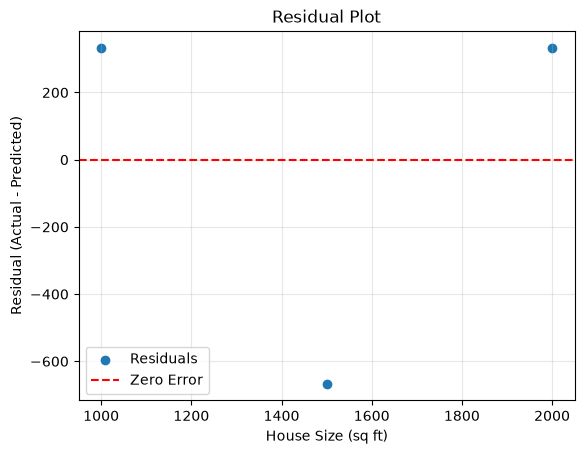

In [50]:
residuals = y-y_pred
print("residuals :",residuals)

plt.scatter(X[:, 0], residuals, label="Residuals")
plt.axhline(y=0, color="red", linestyle="--", label="Zero Error")

plt.title("Residual Plot")
plt.xlabel("House Size (sq ft)")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

##### Note :
The residual plot shows positive residuals at the smallest and largest house sizes and a negative residual at the middle size. This indicates that the model underpredicts the first and third training examples and overpredicts the second. More observations are needed to determine whether the pattern reflects a systematic problem.